# Chapter 42: Same kernel, same predictions

Checks [chapter 42](../../book/42-same-kernel.md). The model is **linear in its weights**, as the theorems require:
the answer at an input is the features of that input matched against the weights. Model A is a Fourier lift, with the
sine and cosine of the fixed frequencies 1 to 4 as features (8 weights). Model B has 30 weights and features that look
nothing like A's: a random isometric image of A's features. NumPy, float64, seeded. These are measurements, not proofs:
the proofs are in `SameKernel.lean`. Run every cell top to bottom. A failed check stops the notebook.

Errors (the residual) are `labels - answers`, and one gradient step adds `learning_rate * train_features^T @ residual`
to the weights, as in chapter 10.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, MODEL, BEFORE, MUTED
import matplotlib.pyplot as plt

use_style()
SEED = 42
TRAIN_COUNT, TEST_COUNT, FREQUENCY_COUNT, BIG_WIDTH = 6, 5, 4, 30
STEP_COUNT = 20000


def make_fourier_features(inputs, frequencies):
    """Row per input: sin and cos of each fixed frequency. A model linear in its weights."""
    angles = np.outer(inputs, frequencies)
    return np.concatenate([np.sin(angles), np.cos(angles)], axis=1)


def match_start_answers(features, weights, target_answers):
    """Smallest change to the weights that makes the answers on these rows equal the targets."""
    return weights + np.linalg.pinv(features) @ (target_answers - features @ weights)


def run_descent(train_features, test_features, labels, start_weights, learning_rate, step_count):
    """Gradient descent. Returns the test answers after every step (step_count + 1 rows) and the final weights."""
    weights = start_weights.copy()
    test_answers = np.empty((step_count + 1, len(test_features)))
    test_answers[0] = test_features @ weights
    for step in range(step_count):
        residual = labels - train_features @ weights
        weights = weights + learning_rate * train_features.T @ residual
        test_answers[step + 1] = test_features @ weights
    return test_answers, weights


generator = np.random.default_rng(SEED)
all_inputs = np.sort(generator.uniform(0.0, 2 * np.pi, TRAIN_COUNT + TEST_COUNT))
test_positions = np.sort(generator.choice(TRAIN_COUNT + TEST_COUNT, TEST_COUNT, replace=False))
is_test = np.zeros(len(all_inputs), dtype=bool)
is_test[test_positions] = True
train_inputs, test_inputs = all_inputs[~is_test], all_inputs[is_test]
labels = np.sin(train_inputs) + 0.5 * generator.standard_normal(TRAIN_COUNT)

# Model A: a Fourier lift with 8 weights.
features_a = make_fourier_features(all_inputs, np.arange(1, FREQUENCY_COUNT + 1))
start_a = 0.5 * generator.standard_normal(features_a.shape[1])
start_answers_all = features_a @ start_a

# Model B: 30 weights, features = A's features mapped by a random matrix with orthonormal rows, so the kernel is the same.
isometry = np.linalg.qr(generator.standard_normal((BIG_WIDTH, features_a.shape[1])))[0].T      # 8 by 30, orthonormal rows
features_b = features_a @ isometry
start_b = match_start_answers(features_b, 0.5 * generator.standard_normal(BIG_WIDTH), start_answers_all)


def split(features):
    return features[~is_test], features[is_test]


train_a, test_a = split(features_a)
train_b, test_b = split(features_b)
print(f"A: {features_a.shape[1]} weights, B: {features_b.shape[1]} weights; "
      f"start weights are different objects (B start has norm {np.linalg.norm(start_b):.3f}, A start {np.linalg.norm(start_a):.3f})")
print("kernel on the training set, largest difference between A and B:", np.abs(train_a @ train_a.T - train_b @ train_b.T).max())
print("test row, largest difference:", np.abs(test_a @ train_a.T - test_b @ train_b.T).max())
print("start residual, largest difference:", np.abs((labels - train_a @ start_a) - (labels - train_b @ start_b)).max())
print("start answer at the test points, largest difference:", np.abs(test_a @ start_a - test_b @ start_b).max())

A: 8 weights, B: 30 weights; start weights are different objects (B start has norm 2.457, A start 0.806)
kernel on the training set, largest difference between A and B: 1.7763568394002505e-15
test row, largest difference: 1.3322676295501878e-15
start residual, largest difference: 1.5543122344752192e-15
start answer at the test points, largest difference: 7.771561172376096e-16


## Claim 1: one step moves the test answer by `learning_rate * test_row . residual` (`gradient_step_moves_a_prediction_through_the_kernel`)

This is an identity of the update rule the code itself applies: the code adds `learning_rate * train_features^T @ residual` to the weights, so the
change of the test answer is that term matched against the test features. Comparing the two is a check **by construction, cannot fail**. It is printed
as a sanity check of the code and is **not counted as evidence** for the chapter. (The evidence for the claim is Claim 2, which trains two different
models and compares their answers.)

In [2]:
LEARNING_RATE_ONE_STEP = 0.01
worst_difference = {"A": 0.0, "B": 0.0}
for trial in range(50):
    for name, train_features, test_features in (("A", train_a, test_a), ("B", train_b, test_b)):
        weights = generator.standard_normal(train_features.shape[1])
        residual = labels - train_features @ weights
        stepped = weights + LEARNING_RATE_ONE_STEP * train_features.T @ residual
        measured_change = test_features @ stepped - test_features @ weights
        predicted_change = LEARNING_RATE_ONE_STEP * (test_features @ train_features.T) @ residual
        worst_difference[name] = max(worst_difference[name], np.abs(measured_change - predicted_change).max())
print(f"[by construction, cannot fail; not evidence] one-step change equals learning_rate * test_row . residual, "
      f"50 random weights, models A and B (largest difference A {worst_difference['A']:.1e}, B {worst_difference['B']:.1e})")

[by construction, cannot fail; not evidence] one-step change equals learning_rate * test_row . residual, 50 random weights, models A and B (largest difference A 9.4e-16, B 3.1e-15)


## Claim 2: same kernel, same test row, same start give the same test answers at every step (`same_kernel_gives_same_predictions`)

Models A and B have the same kernel on the training set and the same test row at all 5 test inputs. Their start weights are
different (B's 30 weights were corrected only so that the residual and the test answers at the start equal A's).
Both train for 20 000 steps at one learning rate, the same for every model in this notebook: one over the largest kernel
eigenvalue, taken over A, B and the controls D and E below.

Predicted: the largest gap between the two models' test answers over all steps and all test points is rounding error,
below `1e-9`. The check fails if it is above. To keep this from being trivial, the test answers must also have moved by
more than 0.1 from their start (so that equal answers are not equal because nothing happened).

Two controls, each breaking one assumption but keeping the start residual and test answers equal to A's:

- **Control D (different kernel).** A Fourier lift with 16 weights and frequencies `0.7, 1.4, ..., 5.6`. Its start is corrected so
  that the residual and the test answers at the start equal A's. Its kernel differs. Predicted: the gap exceeds `1e-3` somewhere.
- **Control E (different test row).** The same features as B on the training inputs (so the same kernel), but the test inputs get
  B's features plus Gaussian noise of size 0.5 in each of the 30 coordinates. Start corrected as for D. Predicted: gap above `1e-3`.

In [3]:
frequencies_d = 0.7 * np.arange(1, 9)
print(f"control D: {2 * len(frequencies_d)} weights, frequencies {frequencies_d[0]:.1f} to {frequencies_d[-1]:.1f}")
features_d = make_fourier_features(all_inputs, frequencies_d)
train_d, test_d = split(features_d)
start_d = match_start_answers(features_d, 0.3 * generator.standard_normal(features_d.shape[1]), start_answers_all)

features_e = features_b.copy()
features_e[is_test] = features_b[is_test] + 0.5 * generator.standard_normal(features_b[is_test].shape)
train_e, test_e = split(features_e)
start_e = match_start_answers(features_e, 0.5 * generator.standard_normal(BIG_WIDTH), start_answers_all)

for name, train_features, test_features, start in (("D", train_d, test_d, start_d), ("E", train_e, test_e, start_e)):
    print(f"control {name}: start residual differs from A by {np.abs((labels - train_features @ start) - (labels - train_a @ start_a)).max():.1e}, "
          f"start test answers differ by {np.abs(test_features @ start - test_a @ start_a).max():.1e}")
print("control D: kernel on the training set differs from A's by", np.abs(train_d @ train_d.T - train_a @ train_a.T).max())
print("control E: test row differs from A's by", np.abs(test_e @ train_e.T - test_a @ train_a.T).max(),
      "and its kernel by", np.abs(train_e @ train_e.T - train_a @ train_a.T).max())

largest_eigenvalue = max(np.linalg.eigvalsh(train_features @ train_features.T).max() for train_features in (train_a, train_b, train_d, train_e))
LEARNING_RATE = 1.0 / largest_eigenvalue
print(f"learning rate {LEARNING_RATE:.5f}")

answers_a, final_a = run_descent(train_a, test_a, labels, start_a, LEARNING_RATE, STEP_COUNT)
answers_b, final_b = run_descent(train_b, test_b, labels, start_b, LEARNING_RATE, STEP_COUNT)
answers_d, final_d = run_descent(train_d, test_d, labels, start_d, LEARNING_RATE, STEP_COUNT)
answers_e, final_e = run_descent(train_e, test_e, labels, start_e, LEARNING_RATE, STEP_COUNT)

gap_b = np.abs(answers_a - answers_b).max(axis=1)      # largest over the test points, at each step
gap_d = np.abs(answers_a - answers_d).max(axis=1)
gap_e = np.abs(answers_a - answers_e).max(axis=1)
moved = np.abs(answers_a[-1] - answers_a[0]).max()

report("same kernel, test row and start: test answers of A and B agree at every one of 20 001 steps",
       gap_b.max() < 1e-9, f"largest gap over steps and test points {gap_b.max():.1e}")
report("the answers did move (so agreement is not for lack of change)", moved > 0.1, f"largest movement {moved:.3f}")
report("control D (different kernel): the gap leaves rounding", gap_d.max() > 1e-3,
       f"largest gap {gap_d.max():.3f}, at step {int(gap_d.argmax())}, at the end {gap_d[-1]:.3f}")
report("control E (different test row): the gap leaves rounding", gap_e.max() > 1e-3,
       f"largest gap {gap_e.max():.3f}, at step {int(gap_e.argmax())}, at the end {gap_e[-1]:.3f}")

control D: 16 weights, frequencies 0.7 to 5.6
control D: start residual differs from A by 5.2e-15, start test answers differ by 3.6e-15
control E: start residual differs from A by 6.7e-15, start test answers differ by 4.3e-15
control D: kernel on the training set differs from A's by 4.000000000000002
control E: test row differs from A's by 2.0808456919872667 and its kernel by 1.7763568394002505e-15
learning rate 0.09432


[PASS] same kernel, test row and start: test answers of A and B agree at every one of 20 001 steps  (largest gap over steps and test points 1.1e-15)
[PASS] the answers did move (so agreement is not for lack of change)  (largest movement 0.998)
[PASS] control D (different kernel): the gap leaves rounding  (largest gap 0.561, at step 28, at the end 0.561)
[PASS] control E (different test row): the gap leaves rounding  (largest gap 0.674, at step 41, at the end 0.674)


True

## Claim 3: the fit training heads for is the same (`same_kernel_gives_same_final_answer`)

The fit is `start_weights + train_features^T @ inverse(kernel) @ start_residual`. The fit itself is the chapter's formula evaluated, so agreement of A's and B's fits is **from the formula**, not measured. The measured part is the descent. Predicted: the test answers at
the fit agree to `1e-9` (from the formula), and 20 000 steps of descent land on the fit to within `1e-6` (the slowest direction of the kernel
contracts by `1 - learning_rate * smallest_eigenvalue` per step; the check fails if 20 000 steps are not enough). Control (from the formula): D's fit,
with the other kernel, differs from A's by more than `1e-3` at some test point.

In [4]:
def get_kernel_fit(train_features, start_weights):
    kernel = train_features @ train_features.T
    start_residual = labels - train_features @ start_weights
    return start_weights + train_features.T @ np.linalg.solve(kernel, start_residual)


fit_answers_a = test_a @ get_kernel_fit(train_a, start_a)
fit_answers_b = test_b @ get_kernel_fit(train_b, start_b)
fit_answers_d = test_d @ get_kernel_fit(train_d, start_d)
smallest_eigenvalue = np.linalg.eigvalsh(train_a @ train_a.T).min()
print(f"smallest kernel eigenvalue {smallest_eigenvalue:.4f}; per-step contraction in its direction {1 - LEARNING_RATE * smallest_eigenvalue:.6f}")

report("[from the formula] test answers at the fit agree between A and B", np.abs(fit_answers_a - fit_answers_b).max() < 1e-9,
       f"largest difference {np.abs(fit_answers_a - fit_answers_b).max():.1e}")
descent_miss = max(np.abs(answers_a[-1] - fit_answers_a).max(), np.abs(answers_b[-1] - fit_answers_b).max())
report("20 000 steps of descent land on the kernel fit, for both models", descent_miss < 1e-6, f"largest miss {descent_miss:.1e}")
report("[from the formula] control: D's fit differs from A's", np.abs(fit_answers_d - fit_answers_a).max() > 1e-3,
       f"largest difference {np.abs(fit_answers_d - fit_answers_a).max():.3f}")
print("fit answers at the test points, A:", np.round(fit_answers_a, 4))
print("fit answers at the test points, B:", np.round(fit_answers_b, 4))
print("fit answers at the test points, D:", np.round(fit_answers_d, 4))

smallest kernel eigenvalue 1.5407; per-step contraction in its direction 0.854687
[PASS] [from the formula] test answers at the fit agree between A and B  (largest difference 6.7e-16)
[PASS] 20 000 steps of descent land on the kernel fit, for both models  (largest miss 5.6e-16)
[PASS] [from the formula] control: D's fit differs from A's  (largest difference 0.561)
fit answers at the test points, A: [ 1.0415  0.8749 -0.8008 -0.7855 -0.7808]
fit answers at the test points, B: [ 1.0415  0.8749 -0.8008 -0.7855 -0.7808]
fit answers at the test points, D: [ 0.4809  0.8137 -1.1097 -1.0966 -1.0754]


## The figure

Left: the test answers of A (solid colour) and B (black dashed) at the 5 test inputs against steps. Right: the largest gap between A and a second
model against steps, on a log axis; zeros are drawn at `1e-17`. B (same kernel and test row) against the two controls.

wrote book/figures/42-same-kernel-same-answers.png


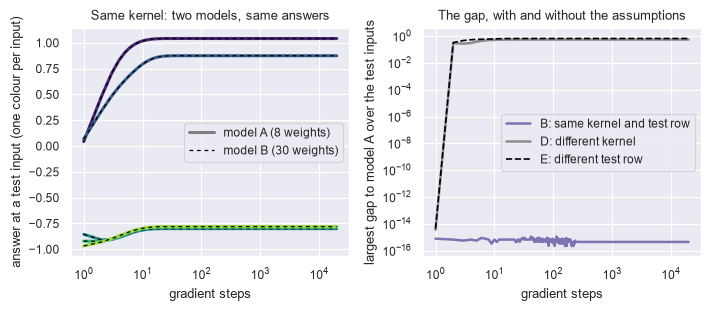

In [5]:
figure, (axis_left, axis_right) = plt.subplots(1, 2, figsize=(7.2, 3.2))
step_axis = np.arange(STEP_COUNT + 1)
shown = np.unique(np.concatenate([np.arange(0, 200), np.geomspace(1, STEP_COUNT, 600).astype(int)]))
palette = plt.cm.viridis(np.linspace(0.1, 0.85, TEST_COUNT))
for point, colour in enumerate(palette):
    axis_left.plot(step_axis[shown] + 1, answers_a[shown, point], color=colour, linewidth=2.2)
    axis_left.plot(step_axis[shown] + 1, answers_b[shown, point], color="black", linestyle=(0, (3, 3)), linewidth=0.9)
axis_left.plot([], [], color="grey", linewidth=2.2, label="model A (8 weights)")
axis_left.plot([], [], color="black", linestyle=(0, (3, 3)), linewidth=0.9, label="model B (30 weights)")
axis_left.set_xscale("log")
axis_left.set_xlabel("gradient steps")
axis_left.set_ylabel("answer at a test input (one colour per input)")
axis_left.set_title("Same kernel: two models, same answers")
axis_left.legend(loc="best")

floor = 1e-17
axis_right.plot(step_axis[shown] + 1, np.maximum(gap_b[shown], floor), color=MODEL, linewidth=1.8, label="B: same kernel and test row")
axis_right.plot(step_axis[shown] + 1, np.maximum(gap_d[shown], floor), color=BEFORE, linewidth=1.8, label="D: different kernel")
axis_right.plot(step_axis[shown] + 1, np.maximum(gap_e[shown], floor), color="black", linewidth=1.2, linestyle="--", label="E: different test row")
axis_right.set_xscale("log")
axis_right.set_yscale("log")
axis_right.set_xlabel("gradient steps")
axis_right.set_ylabel("largest gap to model A over the test inputs")
axis_right.set_title("The gap, with and without the assumptions")
axis_right.legend(loc="center right")
figure.tight_layout()
save_figure(figure, "42-same-kernel-same-answers")
plt.show()